# 282. Do vertebrate gene copies split the ancestral cell types, or does one copy narrow? Setting up the test with Botryllus

**Question.** After the two whole-genome duplications early in vertebrate evolution
([Dehal and Boore 2005](https://doi.org/10.1371/journal.pbio.0030314)), many genes kept two
to four copies (ohnologs). Two outcomes are possible for where those copies are expressed:

- **split** (subfunctionalization; the duplication-degeneration-complementation model of
  [Force et al. 1999](https://doi.org/10.1093/genetics/151.4.1531)): each copy keeps some of
  the ancestral cell types, and together they cover all of them;
- **one narrows** (specialization): one copy keeps every ancestral cell type and another
  copy loses some.

[Marlétaz et al. 2018](https://doi.org/10.1038/s41586-018-0734-6) used amphioxus as the
stand-in for the gene before the duplications, across nine tissues. Over 80% of the broadly
expressed families had a copy that lost tissues, and "one narrows" was more common than
"split". This notebook prepares the same test with a tunicate, *Botryllus schlosseri*, as
the stand-in, and with cell types instead of tissues. Ayelet Voskoboynik's lab has the
Botryllus cell-type expression data; it is not in hand yet.

**What this notebook does.** Stage 0: reproduce the over-80% number from Marlétaz et al.'s
own tables. Stage 1: gene families of Botryllus, Ciona, amphioxus and human, and how many
families can enter the test. Stage 2: the written plan, which waits for Ayelet's data.

**Decision rules, written before any result.**

1. Stage 0. If their supplementary tables rebuild the family fates and the over-80% number,
   Stage 2 reuses their code path. If the tables do not allow it, stop Stage 0 and list what
   is missing; no substitute definition.
2. Stage 1, the go/no-go for Stage 2. Marlétaz et al.'s script tested 360-370 of the
   1,097-1,215 ohnolog families left after its size filter: 30-34% are expressed in every
   one of the nine tissues in both species, the filter every family must pass. If at least
   **330** families have exactly one Botryllus gene and two or more human ohnologs, 30% of
   them gives about 100 testable families, and Stage 2 goes ahead with Botryllus. The 30%
   comes from bulk tissue RNA; single-cell detection in about five coarse cell-type groups
   may pass a different share, so the count is checked again once the data arrive. Below 330,
   Stage 2 starts with Ciona or amphioxus as the stand-in and Botryllus as a check.
3. Stage 1, tunicate gene loss ([Berná and Alvarez-Valin 2014](https://doi.org/10.1093/gbe/evu122):
   tunicate genomes change fast and have lost genes). Among families with one amphioxus
   gene and two or more human ohnologs, if Botryllus has no copy in more than **25%**, the
   families that remain are a biased sample (Botryllus kept only some kinds of genes), and
   the Stage 2 result is reported as "for genes Botryllus kept", not for vertebrate
   ohnologs in general.

**What it decides.** Whether Botryllus cell types can stand in for the ancestral gene in
this test (rule 2), and how far a Botryllus answer can be generalized (rule 3).

The Botryllus histocompatibility factor (BHF) is not part of this test: it has no human
relative, so it cannot enter a tunicate-vertebrate family comparison.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import ohnolog_family_utils as ofu
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(12)
pl.Config.set_fmt_str_lengths(60)

FIG_DIR = Path("../figures")
TABLE_DIR = Path(".")
PROTEOMES = ofu.DATA_282 / "proteomes"
# OrthoFinder output copied back from Sherlock (notebooks/282_orthofinder.sbatch).
ORTHOFINDER_RESULTS = Path(
    __import__("os").environ.get(
        "NB282_ORTHOFINDER", ofu.DATA_282 / "orthofinder/Results_282"
    )
)
ORTHOGROUPS = ORTHOFINDER_RESULTS / "Orthogroups/Orthogroups.tsv"
HAVE_ORTHOFINDER = ORTHOGROUPS.exists()
OHNOLOG_CRITERION = (
    "strict"  # main analysis; intermediate and relaxed are shown as checks
)
GO_THRESHOLD = 330  # decision rule 2
LOSS_THRESHOLD = 0.25  # decision rule 3
print(
    "OrthoFinder families:",
    ORTHOGROUPS,
    "found" if HAVE_ORTHOFINDER else "NOT FOUND (Sherlock run pending)",
)

OrthoFinder families: /Users/olga/data/282-ohnolog-families/orthofinder/Results_282/Orthogroups/Orthogroups.tsv NOT FOUND (Sherlock run pending)


## Stage 0. Reproduce the over-80% number from Marlétaz et al.'s own tables

**Sources** (downloaded 2026-10-12 to `~/data/marletaz2018/`):

- Supplementary Data 2 (`41586_2018_734_MOESM4_ESM.zip`), Supplementary Datasets 1-17.
  Dataset 7: all 21,576 gene families of 11 species, gene IDs per family. Dataset 9: the
  1,509 ohnolog families and 2,511 single-copy families. No tunicate is among the 11 species.
- Supplementary Tables (`MOESM5`): Table 7, the nine tissues matched across amphioxus,
  zebrafish, mouse and frog.
- Supplementary Information (`MOESM1`), section 11: the rules. A gene is "on" in a tissue
  if its normalized cRPKM (reads per kilobase of uniquely mappable positions per million
  reads, quantile-normalized across samples) is above 5.
- Their code, [gitlab.com/FunctionalAmphioxus/overview](https://gitlab.com/FunctionalAmphioxus/overview)
  (commit 26dcf27b): `main-figures/Analyze_Red_Subf_Spec.pl` classifies the families, and
  `main-figures/F6ae.md` prints its output for mouse, zebrafish and frog.

**Their rule**, ported to `ofu.classify_family_marletaz` and tested branch by branch in
`scripts/tests/test_ohnolog_family_utils.py`. A family enters only if the single amphioxus
gene is on in all nine tissues, and the vertebrate copies together are on in all nine too.
Then: every copy on in all nine is **redundant**; no copy on in all nine is
**subfunctionalized** (split); some copy on in all nine and another not is **specialized**
(one narrows), "strong" if a narrowed copy keeps 2 tissues or fewer, "mild" otherwise.

In [2]:
d7 = ofu.read_marletaz_families(7)
d9 = ofu.read_marletaz_families(9, "Ohnologs")
d9_one = ofu.read_marletaz_families(9, "1-to-1")
print(
    f"Dataset 7: {d7['family_id'].n_unique():_} families, {d7.height:_} genes, species: {sorted(d7['species'].unique())}"
)
print(
    f"Dataset 9: {d9['family_id'].n_unique():_} ohnolog families, {d9_one['family_id'].n_unique():_} single-copy families"
)

# The script's first filter, rebuilt from Dataset 7: at most one amphioxus gene, two or more
# copies in the vertebrate. The script counts only genes that also have expression values,
# which are not public, so its number can differ from this one in either direction (a
# family with two amphioxus genes, one without expression, passes in the script).
counts = (
    d7.filter(pl.col("family_id").is_in(d9["family_id"].unique().implode()))
    .group_by("family_id", "species")
    .len()
    .pivot(on="species", index="family_id", values="len")
    .fill_null(0)
)
rows = []
for r in ofu.MARLETAZ_PUBLISHED_FATES.iter_rows(named=True):
    sp = r["code"]
    rows.append(
        {
            "vertebrate": r["species"],
            "ohnolog families (Dataset 9)": counts.height,
            "script: start": r["ohnolog_families_start"],
            "rebuilt: <=1 amphioxus, >=2 copies": counts.filter(
                (pl.col("Bla") <= 1) & (pl.col(sp) >= 2)
            ).height,
            "script: after size filter (needs expression)": r["after_size_filter"],
            "script: expressed in all 9 in both": r["valid_all_nine_domains"],
        }
    )
stage0_filters = pl.DataFrame(rows)
stage0_filters

/Users/olga/anaconda3/envs/2025-kmerseek-analysis/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Dataset 7: 21_576 families, 180_707 genes, species: ['Bbe', 'Bla', 'Cmi', 'Dre', 'Gga', 'Hsa', 'Mmu', 'Ola', 'Sko', 'Spu', 'Xtr']
Dataset 9: 1_509 ohnolog families, 2_511 single-copy families


vertebrate,ohnolog families (Dataset 9),script: start,"rebuilt: <=1 amphioxus, >=2 copies",script: after size filter (needs expression),script: expressed in all 9 in both
str,i64,i64,i64,i64,i64
"""mouse""",1509,1509,1225,1215,370
"""zebrafish""",1509,1509,1140,1142,366
"""frog""",1509,1509,1094,1097,360


Families expressed in all nine tissues in amphioxus and in the vertebrate copies together,
by fate. Counts are the script's printed output (F6ae.md); percentages computed here.
shape: (3, 9)
┌──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ species  ┆ valid_al ┆ redundan ┆ subfunct ┆ speciali ┆ speciali ┆ pct_lost ┆ pct_spec ┆ pct_subf │
│ ---      ┆ l_nine_d ┆ t        ┆ ionalize ┆ zed_mild ┆ zed_stro ┆ _a_tissu ┆ ialized  ┆ unctiona │
│ str      ┆ omains   ┆ ---      ┆ d        ┆ ---      ┆ ng       ┆ e        ┆ ---      ┆ lized    │
│          ┆ ---      ┆ i64      ┆ ---      ┆ i64      ┆ ---      ┆ ---      ┆ f64      ┆ ---      │
│          ┆ i64      ┆          ┆ i64      ┆          ┆ i64      ┆ f64      ┆          ┆ f64      │
╞══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ mouse    ┆ 370      ┆ 46       ┆ 80       ┆ 167      ┆ 77       ┆ 87.6     ┆ 65.9     ┆ 21.6     │
│

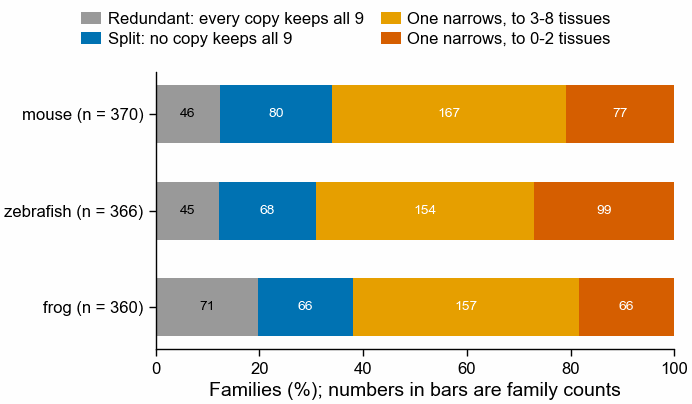

In [3]:
fates = ofu.MARLETAZ_PUBLISHED_FATES.with_columns(
    (
        pl.col("subfunctionalized")
        + pl.col("specialized_strong")
        + pl.col("specialized_mild")
    ).alias("lost_a_tissue"),
    (pl.col("specialized_strong") + pl.col("specialized_mild")).alias("specialized"),
).with_columns(
    (100 * pl.col("lost_a_tissue") / pl.col("valid_all_nine_domains"))
    .round(1)
    .alias("pct_lost_a_tissue"),
    (100 * pl.col("specialized") / pl.col("valid_all_nine_domains"))
    .round(1)
    .alias("pct_specialized"),
    (100 * pl.col("subfunctionalized") / pl.col("valid_all_nine_domains"))
    .round(1)
    .alias("pct_subfunctionalized"),
)
print(
    "Families expressed in all nine tissues in amphioxus and in the vertebrate copies together,"
)
print(
    "by fate. Counts are the script's printed output (F6ae.md); percentages computed here."
)
print(
    fates.select(
        "species",
        "valid_all_nine_domains",
        "redundant",
        "subfunctionalized",
        "specialized_mild",
        "specialized_strong",
        "pct_lost_a_tissue",
        "pct_specialized",
        "pct_subfunctionalized",
    )
)

order = [
    ("redundant", "Redundant: every copy keeps all 9", pf.GREY),
    ("subfunctionalized", "Split: no copy keeps all 9", pf.OKABE_ITO["blue"]),
    ("specialized_mild", "One narrows, to 3-8 tissues", pf.OKABE_ITO["orange"]),
    ("specialized_strong", "One narrows, to 0-2 tissues", pf.OKABE_ITO["vermillion"]),
]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 52)
y = np.arange(fates.height)
left = np.zeros(fates.height)
for col, label, colour in order:
    share = (fates[col] / fates["valid_all_nine_domains"]).to_numpy() * 100
    ax.barh(y, share, left=left, color=colour, label=label, height=0.6)
    for yi, l, s, n in zip(y, left, share, fates[col]):
        ax.text(
            l + s / 2,
            yi,
            f"{n}",
            ha="center",
            va="center",
            fontsize=5,
            color="white" if colour != pf.GREY else "black",
        )
    left += share
ax.set_yticks(
    y,
    [
        f"{s} (n = {n})"
        for s, n in zip(fates["species"], fates["valid_all_nine_domains"])
    ],
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Families (%); numbers in bars are family counts")
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG_DIR / "282_marletaz2018_fig6d_fates_from_published_counts")

**Reading the figure.** One bar per vertebrate, 100% = the families whose single amphioxus
gene and whose vertebrate copies together are expressed in all nine tissues. Everything
that is not grey is a family where some copy lost a tissue: 80.3% (frog), 87.6% (mouse),
87.7% (zebrafish), the paper's "between 80 and 88%". "One narrows" (orange + vermillion)
is 3.0 to 3.7 times more common than "split" (blue) in all three. These are the authors'
own counts; this notebook did not recompute them from expression.

### Stage 0 stops here: what is missing

The family fates cannot be rebuilt from the published tables. The classification needs,
for every gene, its expression in the nine tissues. The script reads four files,
`Bla_cRPKMs-TissuesC-s-NORM.tab`, `Mmu_...`, `Dre_...` and `Xtr_...`. None is public, and
the per-sample tables they were built from are public for amphioxus only:

| Needed | Where looked (2026-10-12) | Found |
|---|---|---|
| The four normalized tables the script reads | Supplementary Data 1-2, Supplementary Tables, GitLab FunctionalAmphioxus (every file in both projects), amphiencode.github.io/Data, Zenodo, figshare | no |
| Amphioxus per-sample cRPKM, the nine tissues | GEO GSE106430 supplementary files (BL gene IDs, one file per replicate) | yes |
| Mouse per-sample cRPKM, their nine samples (`Oocyte_M`, `Testis_B12`, ...) | VastDB mm10 expression table (Irimia lab, same cRPKM method) | 1 of 9 (`Skin_a`) |
| Zebrafish, their nine samples (`Eggs_A`, `Brain_a`, ...) | VastDB danRer10; GEO GSE106430 (embryo stages only) | 5 of 9 (no testis, intestine, liver, brain) |
| Frog | VastDB (no *Xenopus*) | no |
| Gene families, ohnolog list, tissue matching, the rule, the code | Datasets 7 and 9, Table 7, SI section 11, the Perl script | yes |

With no vertebrate side, the amphioxus tables alone cannot classify a family. Filling the
vertebrate side would mean re-mapping each vertebrate's raw RNA-seq (the SRA runs in
Supplementary Dataset 3) with their mappability correction: a new data set, not their
tables, so it is not done here. What could be checked from the tables did agree: Dataset 9 holds the 1,509 families the
script starts from, and the rebuilt size filter (1,225 / 1,140 / 1,094) is within 10
families of the script's (1,215 / 1,142 / 1,097), the gap the missing expression filter
allows.

For Stage 2 this means the rule (`ofu.classify_family_marletaz`) is reused as written, and
the over-80% number is taken from their printed counts, not reproduced.

## Stage 1a. The four proteomes, one protein per gene

OrthoFinder groups proteins. A gene with three isoforms would count as three copies, so
each proteome is cut to one protein per gene first (`scripts/prepare_282_proteomes.py`):

- **Botryllus**: the proteome the dark-set run used, `Eukaryota/BOTSCH2026_30301.fasta`.
  2,019 gene names there carry 2-6 isoforms each; the longest is kept. Ayelet's newer
  genome replaces it with `--botryllus <fasta>`.
- **Human**: the 19,732 GENCODE v49 canonical proteins of notebooks 241-256.
- **Amphioxus**: *Branchiostoma lanceolatum*, the reference protein per coding locus from
  Marlétaz et al. (amphiencode.github.io/Data), so families can be checked against theirs.
- **Ciona**: the Quest for Orthologs 2020_04 reference proteome UP000008144 (*Ciona
  intestinalis*), a solitary tunicate.

shape: (4, 6)
┌───────────┬──────────────────┬────────────┬───────────────┬──────────────┬───────────────────────┐
│ species   ┆ proteins_in_file ┆ genes_kept ┆ stops_removed ┆ sha256       ┆ file                  │
│ ---       ┆ ---              ┆ ---        ┆ ---           ┆ ---          ┆ ---                   │
│ str       ┆ i64              ┆ i64        ┆ i64           ┆ str          ┆ str                   │
╞═══════════╪══════════════════╪════════════╪═══════════════╪══════════════╪═══════════════════════╡
│ botryllus ┆ 45339            ┆ 42745      ┆ 0             ┆ 10ae9f5b033f ┆ BOTSCH2026_30301.fast │
│           ┆                  ┆            ┆               ┆              ┆ a                     │
│ human     ┆ 19732            ┆ 19732      ┆ 0             ┆ b6cdd87804d4 ┆ gencode.v49.pc_transl │
│           ┆                  ┆            ┆               ┆              ┆ ations.canonical.fa   │
│ amphioxus ┆ 35956            ┆ 35956      ┆ 29538         ┆ 196b06a95bbf ┆ 

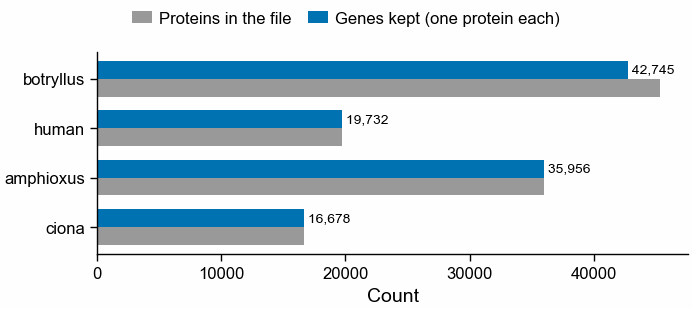

In [4]:
inputs = json.loads((PROTEOMES / "inputs.json").read_text())
proteomes = pl.DataFrame(
    [
        {
            "species": s,
            "proteins_in_file": v["records_in"],
            "genes_kept": v["genes_out"],
            "stops_removed": v["trailing_stops_removed"],
            "sha256": v["sha256"][:12],
            "file": Path(v["path"]).name,
        }
        for s, v in inputs.items()
    ]
)
print(proteomes)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
y = np.arange(proteomes.height)
ax.barh(
    y + 0.18,
    proteomes["proteins_in_file"],
    height=0.36,
    color=pf.GREY,
    label="Proteins in the file",
)
ax.barh(
    y - 0.18,
    proteomes["genes_kept"],
    height=0.36,
    color=pf.OKABE_ITO["blue"],
    label="Genes kept (one protein each)",
)
for yi, n in zip(y, proteomes["genes_kept"]):
    ax.text(n, yi - 0.18, f" {n:,}", va="center", fontsize=5)
ax.set_yticks(y, proteomes["species"])
ax.invert_yaxis()
ax.set_xlabel("Count")
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG_DIR / "282_proteomes_botryllus_ciona_amphioxus_human_genes_kept")

## Stage 1b. Gene families with OrthoFinder, and which human copies are ohnologs

**Why OrthoFinder** ([Emms and Kelly 2019](https://doi.org/10.1186/s13059-019-1832-y)):
it clusters proteins into families from all-against-all DIAMOND scores and infers a gene
tree for each family, and it was the most accurate ortholog method on the
Quest for Orthologs benchmark. Its families hold every copy in every species, which is the
unit this test needs (one Botryllus gene against all its human copies). kmerseek is not
used: most tunicate-human pairs are below the sequence identity where kmerseek places
features well.

The run (`notebooks/282_orthofinder.sbatch`, OrthoFinder 3.1.5,
`quay.io/biocontainers/orthofinder:3.1.5--hdfd78af_0`) gets the species tree
`(amphioxus,(human,(botryllus,ciona)))` (`notebooks/282_species_tree.nwk`) instead of
inferring one: four species are too few to root a tree reliably. Families are rooted at the
chordate ancestor (`Orthogroups/Orthogroups.tsv`; OrthoFinder 3.1 writes the root-level
families there).

**Which human copies come from the two duplications.** OHNOLOGS v2
([Singh and Isambert 2020](https://doi.org/10.1093/nar/gkz909)), human 2R pairs,
downloaded 2026-10-12 from ohnologs.curie.fr (`~/data/ohnologs_v2/`). Three confidence
levels: strict (4,258 pairs, 4,254 once the 4 pairs listed twice are removed; the main analysis here), intermediate (5,644) and relaxed
(7,358, the number the paper gives for human). A human gene counts as an ohnolog of a
family only if one of its OHNOLOGS partners is in the same family.

OHNOLOGS v2 uses Ensembl 84 gene IDs; GENCODE v49 is Ensembl 115. IDs found in the 19,732 canonical genes:
shape: (3, 7)
┌──────────────┬───────┬──────────────┬───────┬─────────────────┬─────────────────┬────────────────┐
│ criterion    ┆ pairs ┆ unique_pairs ┆ genes ┆ genes_in_gencod ┆ pairs_with_both ┆ pct_genes_foun │
│ ---          ┆ ---   ┆ ---          ┆ ---   ┆ e_v49_canonical ┆ _genes          ┆ d              │
│ str          ┆ i64   ┆ i64          ┆ i64   ┆ ---             ┆ ---             ┆ ---            │
│              ┆       ┆              ┆       ┆ i64             ┆ i64             ┆ f64            │
╞══════════════╪═══════╪══════════════╪═══════╪═════════════════╪═════════════════╪════════════════╡
│ strict       ┆ 4258  ┆ 4254         ┆ 4940  ┆ 4881            ┆ 4153            ┆ 98.8           │
│ intermediate ┆ 5644  ┆ 5640         ┆ 5964  ┆ 5882            ┆ 5490            ┆ 98.6           │
│ relaxed      ┆ 7358  ┆ 7354         ┆ 6870  ┆ 6767            ┆ 7154 

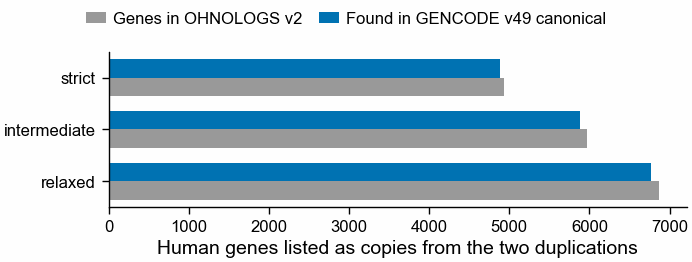

In [5]:
ohnolog_pairs = {c: ofu.read_ohnolog_pairs(c) for c in ofu.OHNOLOG_CRITERIA}
human_ids = {l[1:].strip() for l in open(PROTEOMES / "human.fa") if l.startswith(">")}
coverage = pl.DataFrame(
    [
        {
            "criterion": c,
            "pairs": p.height,
            "unique_pairs": p.select(
                pl.min_horizontal("ohno1", "ohno2").alias("a"),
                pl.max_horizontal("ohno1", "ohno2").alias("b"),
            )
            .unique()
            .height,
            "genes": len(set(p["ohno1"]) | set(p["ohno2"])),
            "genes_in_gencode_v49_canonical": len(
                (set(p["ohno1"]) | set(p["ohno2"])) & human_ids
            ),
            "pairs_with_both_genes": p.filter(
                pl.col("ohno1").is_in(list(human_ids))
                & pl.col("ohno2").is_in(list(human_ids))
            ).height,
        }
        for c, p in ohnolog_pairs.items()
    ]
).with_columns(
    (100 * pl.col("genes_in_gencode_v49_canonical") / pl.col("genes"))
    .round(1)
    .alias("pct_genes_found")
)
print(
    "OHNOLOGS v2 uses Ensembl 84 gene IDs; GENCODE v49 is Ensembl 115. IDs found in the 19,732 canonical genes:"
)
print(coverage)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 34)
y = np.arange(coverage.height)
ax.barh(
    y + 0.18,
    coverage["genes"],
    height=0.36,
    color=pf.GREY,
    label="Genes in OHNOLOGS v2",
)
ax.barh(
    y - 0.18,
    coverage["genes_in_gencode_v49_canonical"],
    height=0.36,
    color=pf.OKABE_ITO["blue"],
    label="Found in GENCODE v49 canonical",
)
ax.set_yticks(y, coverage["criterion"])
ax.invert_yaxis()
ax.set_xlabel("Human genes listed as copies from the two duplications")
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG_DIR / "282_ohnologs_v2_human_genes_found_in_gencode_v49")

In [6]:
if HAVE_ORTHOFINDER:
    genes = ofu.read_orthogroups(ORTHOGROUPS)
    tables = {c: ofu.family_table(genes, p) for c, p in ohnolog_pairs.items()}
    families = tables[OHNOLOG_CRITERION]
    print(
        f"{families.height:_} families (OrthoFinder orthogroups with 2 or more genes)"
    )
    print(genes.group_by("species").len("genes_in_families").sort("species"))
else:
    genes = tables = families = None
    print(
        "Waiting for the Sherlock OrthoFinder run; Stage 1 numbers below are not computed yet."
    )

Waiting for the Sherlock OrthoFinder run; Stage 1 numbers below are not computed yet.


## Stage 1c. Families with one Botryllus gene and two or more human ohnologs

The output table (`notebooks/282_families_botryllus1_human_ohnologs2plus.tsv`) has one row
per family with exactly one Botryllus gene and two or more human ohnologs: family id,
Botryllus gene, Ciona genes, amphioxus genes, human ohnologs (Ensembl gene ID and symbol).
The figure counts every family by its number of Botryllus copies and human ohnologs; the
boxed cells are the families Stage 2 can test. A family never has exactly one human
ohnolog, because an ohnolog needs its partner in the same family.

In [7]:
if HAVE_ORTHOFINDER:
    symbol = {}
    for p in ohnolog_pairs.values():
        symbol.update(dict(zip(p["ohno1"], p["symbol1"])))
        symbol.update(dict(zip(p["ohno2"], p["symbol2"])))
    target = families.filter(
        (pl.col("n_botryllus") == 1) & (pl.col("n_human_ohnologs") >= 2)
    )
    out = target.select(
        "family_id",
        pl.col("botryllus_genes").list.join(";").alias("botryllus_genes"),
        pl.col("ciona_genes").list.join(";").alias("ciona_genes"),
        pl.col("amphioxus_genes").list.join(";").alias("amphioxus_genes"),
        pl.col("human_ohnologs")
        .list.eval(pl.element() + "|" + pl.element().replace_strict(symbol, default=""))
        .list.join(";")
        .alias("human_ohnologs"),
        "n_ciona",
        "n_amphioxus",
        "n_human_ohnologs",
        "n_human",
    )
    out.write_csv(
        TABLE_DIR / "282_families_botryllus1_human_ohnologs2plus.tsv", separator="\t"
    )

    summary = pl.DataFrame(
        [
            {
                "criterion": c,
                "families_botryllus1_ohnologs2plus": t.filter(
                    (pl.col("n_botryllus") == 1) & (pl.col("n_human_ohnologs") >= 2)
                ).height,
                "of_which_amphioxus1": t.filter(
                    (pl.col("n_botryllus") == 1)
                    & (pl.col("n_human_ohnologs") >= 2)
                    & (pl.col("n_amphioxus") == 1)
                ).height,
                "of_which_ciona1": t.filter(
                    (pl.col("n_botryllus") == 1)
                    & (pl.col("n_human_ohnologs") >= 2)
                    & (pl.col("n_ciona") == 1)
                ).height,
                "families_with_2plus_ohnologs_any_botryllus": t.filter(
                    pl.col("n_human_ohnologs") >= 2
                ).height,
            }
            for c, t in tables.items()
        ]
    )
    print(summary)
    n_go = summary.filter(pl.col("criterion") == OHNOLOG_CRITERION)[
        "families_botryllus1_ohnologs2plus"
    ][0]
    print(
        f"Decision rule 2 ({OHNOLOG_CRITERION}): {n_go:_} families vs threshold {GO_THRESHOLD}: "
        + (
            "GO, Botryllus is the stand-in"
            if n_go >= GO_THRESHOLD
            else "BELOW, start with Ciona or amphioxus"
        )
    )

    grid = ofu.copy_number_grid(families)
    print(grid)
    rows_b = list(range(0, 6))
    cols_h = [0, 2, 3, 4, 5]
    mat = np.zeros((len(rows_b), len(cols_h)), dtype=int)
    for r in grid.iter_rows(named=True):
        mat[
            rows_b.index(r["botryllus_copies"]), cols_h.index(r["human_ohnolog_copies"])
        ] = r["n_families"]
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 62)
    # Light end starts at a mid tint so 1 family still shows against white; 0 is left white.
    cmap = plt.matplotlib.colors.ListedColormap(
        plt.get_cmap("cividis_r")(np.linspace(0.15, 1, 256))
    )
    cmap.set_bad("white")
    im = ax.imshow(
        np.ma.masked_equal(np.log10(mat + 1), 0),
        cmap=cmap,
        aspect="auto",
        vmin=np.log10(2),
    )
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = np.log10(mat[i, j] + 1) / max(np.log10(mat.max() + 1), 1e-9)
            ax.text(
                j,
                i,
                f"{mat[i, j]:,}",
                ha="center",
                va="center",
                fontsize=5,
                color="white" if v > 0.6 else ("black" if mat[i, j] else pf.GREY),
            )
    j0 = cols_h.index(2)
    ax.add_patch(
        plt.Rectangle(
            (j0 - 0.5, 0.5),
            len(cols_h) - j0,
            1,
            fill=False,
            lw=1.2,
            ec="black",
            label="Families Stage 2 can test (1 Botryllus gene, 2+ ohnologs)",
        )
    )
    ax.set_xticks(range(len(cols_h)), ["0", "2", "3", "4", "5+"])
    ax.set_yticks(range(len(rows_b)), ["0", "1", "2", "3", "4", "5+"])
    ax.set_xlabel(
        f"Human ohnolog copies in the family (OHNOLOGS v2, {OHNOLOG_CRITERION})"
    )
    ax.set_ylabel("Botryllus genes in the family")
    cb = fig.colorbar(im, ax=ax, shrink=0.8)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000] if t <= mat.max()]
    cb.set_ticks(np.log10(np.array(ticks) + 1), labels=[f"{t:,}" for t in ticks])
    cb.set_label("Families")
    pf.shared_legend(fig, ncol=1)
    pf.save(
        fig,
        FIG_DIR
        / "282_families_by_botryllus_copies_and_human_ohnologs_orthofinder_ohnologs_v2",
    )

## Stage 1d. Tunicate gene loss: families Botryllus is missing from

Among families with exactly one amphioxus gene and two or more human ohnologs (the gene
was single before the duplications and kept by vertebrates), how often does Botryllus
have no copy, and is Ciona missing too? Missing in both tunicates points to a loss in the
tunicate ancestor; missing in Botryllus only points to a Botryllus loss or a gene the
Botryllus annotation did not find.

In [8]:
if HAVE_ORTHOFINDER:
    base = families.filter(
        (pl.col("n_amphioxus") == 1) & (pl.col("n_human_ohnologs") >= 2)
    )
    loss = (
        base.with_columns(
            pl.when(pl.col("n_botryllus") == 0)
            .then(pl.lit("0"))
            .when(pl.col("n_botryllus") == 1)
            .then(pl.lit("1"))
            .otherwise(pl.lit("2+"))
            .alias("botryllus"),
            pl.when(pl.col("n_ciona") == 0)
            .then(pl.lit("Ciona: none"))
            .otherwise(pl.lit("Ciona: 1 or more"))
            .alias("ciona"),
        )
        .group_by("botryllus", "ciona")
        .len("families")
        .sort("botryllus", "ciona")
    )
    print(
        f"{base.height:_} families with one amphioxus gene and 2+ human ohnologs ({OHNOLOG_CRITERION})"
    )
    print(loss)
    missing = base.filter(pl.col("n_botryllus") == 0).height
    frac = missing / base.height if base.height else float("nan")
    print(
        f"Botryllus has no copy in {missing:_} of {base.height:_} ({100 * frac:.1f}%); "
        f"decision rule 3 threshold {100 * LOSS_THRESHOLD:.0f}%: "
        + (
            "ABOVE, report Stage 2 as 'for genes Botryllus kept'"
            if frac > LOSS_THRESHOLD
            else "below"
        )
    )
    families.filter(
        (pl.col("n_botryllus") == 0)
        & (pl.col("n_amphioxus") == 1)
        & (pl.col("n_human_ohnologs") >= 2)
    ).select(
        "family_id",
        pl.col("ciona_genes").list.join(";"),
        pl.col("amphioxus_genes").list.join(";"),
        pl.col("human_ohnologs").list.join(";"),
    ).write_csv(
        TABLE_DIR / "282_families_botryllus0_amphioxus1_human_ohnologs2plus.tsv",
        separator="\t",
    )

    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 42)
    cats = ["0", "1", "2+"]
    width = 0.38
    for k, (c, colour) in enumerate(
        [
            ("Ciona: none", pf.OKABE_ITO["vermillion"]),
            ("Ciona: 1 or more", pf.OKABE_ITO["blue"]),
        ]
    ):
        vals = [
            loss.filter((pl.col("botryllus") == b) & (pl.col("ciona") == c))[
                "families"
            ].sum()
            for b in cats
        ]
        xs = np.arange(len(cats)) + (k - 0.5) * width
        ax.bar(xs, vals, width=width, color=colour, label=c)
        for x, v in zip(xs, vals):
            ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=5)
    ax.set_xticks(range(len(cats)), cats)
    ax.set_xlabel(
        "Botryllus genes in the family\n(only families with 1 amphioxus gene and 2+ human ohnologs)"
    )
    ax.set_ylabel("Families")
    pf.shared_legend(fig, ncol=2)
    pf.save(
        fig, FIG_DIR / "282_tunicate_gene_loss_botryllus_ciona_orthofinder_ohnologs_v2"
    )

## Stage 1e. Check the families against Marlétaz et al.'s

For each of their ohnolog families with exactly one amphioxus gene and two or more human
genes, does our run put that amphioxus gene in the same family as their human genes? Their
human IDs are Ensembl 80; a gene whose ID is not in GENCODE v49 counts as "not together".

In [9]:
if HAVE_ORTHOFINDER:
    agree = ofu.compare_with_marletaz(genes, d9)
    order_a = [
        "all human copies together",
        "some",
        "none",
        "amphioxus gene not in a family",
    ]
    agree_counts = (
        agree.group_by("agreement")
        .len("families")
        .with_columns(
            pl.col("agreement")
            .replace_strict({a: i for i, a in enumerate(order_a)})
            .alias("o")
        )
        .sort("o")
        .drop("o")
    )
    hsa_ids = set(d9.filter(pl.col("species") == "Hsa")["gene_id"])
    print(
        f"{agree.height:_} Marlétaz families (1 amphioxus gene, 2+ human genes); "
        f"{len(hsa_ids & human_ids):_} of their {len(hsa_ids):_} human gene IDs are in GENCODE v49 canonical"
    )
    print(agree_counts)
    agree.write_csv(
        TABLE_DIR / "282_orthofinder_vs_marletaz2018_ohnolog_families.tsv",
        separator="\t",
    )
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 36)
    vals = [
        agree_counts.filter(pl.col("agreement") == a)["families"].sum() for a in order_a
    ]
    colours = [
        pf.OKABE_ITO["bluish_green"],
        pf.OKABE_ITO["orange"],
        pf.OKABE_ITO["vermillion"],
        pf.GREY,
    ]
    ax.barh(range(len(order_a)), vals, color=colours)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:,}", va="center", fontsize=5)
    ax.set_yticks(range(len(order_a)), order_a)
    ax.invert_yaxis()
    ax.set_xlabel("Marlétaz et al. ohnolog families")
    pf.save(fig, FIG_DIR / "282_orthofinder_vs_marletaz2018_ohnolog_families")

## Stage 2. Plan (waits for Ayelet Voskoboynik's data)

Written 2026-10-12, before any Botryllus cell-type expression has been seen. The rules are
code already: `ofu.classify_copies_against_ancestor`, tested in
`scripts/tests/test_ohnolog_family_utils.py`.

**Input needed from the Voskoboynik lab.** A gene x cell type table for Botryllus with, for
each gene and cell type: mean expression, the fraction of cells where the gene is detected,
and the number of cells in that cell type. Plus the genome and annotation version the gene
IDs come from, so the families above can be rebuilt on the same proteome
(`scripts/prepare_282_proteomes.py --botryllus <fasta>`).

**Human side.** Tabula Sapiens ([Tabula Sapiens Consortium 2022](https://doi.org/10.1126/science.abl4896)),
summarized the same way (mean, fraction detected, cell count per cell type).

**Matching cell types across species.** Start coarse: blood cells, muscle, neurons,
epithelia, germ cells. Which Botryllus cell types go into which group is Ayelet's call,
not ours.

**Classification** (following Marlétaz et al.; a gene is "on" in a cell type if detected in
at least a set fraction of its cells, the fraction fixed before the data are opened):

- Only families whose Botryllus gene is on in every matched cell type are tested (their
  "expressed in all nine" filter).
- **both keep all**: every human copy is on in every matched cell type;
- **one narrows**: at least one copy keeps every cell type, at least one does not;
- **split**: no copy keeps every cell type, but together they cover all;
- **cell type lost**: the copies together miss one; reported, not tested;
- **new cell type**: a copy is on in a matched cell type where the Botryllus gene is off;
  reported beside the fate.

**Compare copies at matched expression levels.** After duplication each copy is often
expressed lower ([Qian et al. 2010](https://doi.org/10.1016/j.tig.2010.07.002)), and a
lower-expressed gene is detected in fewer cells, so it can look narrowed only because it
is harder to detect. Control: human genes in one-to-one families (one Botryllus gene, one
human gene), binned by mean expression. A copy counts as narrowed only if it loses more
cell types than 95% of the one-to-one genes in its expression bin. As a check, also sum the
copies' expression per cell type and call on/off on the sum (Marlétaz et al. did this for
their Fig. 6a-b histograms, not for the fates).

Each gene gets one on/off call per cell type, and the copies' union is built from those
same calls. Their Perl script differs here: it rounds a gene's value to two decimals for
the gene's own calls but not for the family union, so a value just above 5 can be "on" for
the family and "off" for the gene.

**Prediction.** If Botryllus agrees with amphioxus, most tested families are "one narrows",
not "split" (Marlétaz et al.: 3.0-3.7 times more often).

**Questions for Ayelet.**
1. Which data set to start with?
2. Which genome and annotation version are its gene IDs from?
3. How do her cell types map to vertebrate cell types (blood, muscle, neurons, epithelia,
   germ cells)?

## Summary

- **Stage 0.** The over-80% number cannot be rebuilt from Marlétaz et al.'s published
  tables: the per-gene expression tables their script reads are not in the supplement, on
  their GitLab, or on their data page. Their printed counts give 80.3% (frog), 87.6%
  (mouse) and 87.7% (zebrafish) of broadly expressed ohnolog families with a copy that lost
  a tissue, and "one narrows" 3.0-3.7 times more often than "split". Their family filter,
  rebuilt from Datasets 7 and 9, comes within 10 families of the script's.
- **Stage 1.** Proteomes are prepared (Botryllus 42,745 genes, human 19,732, amphioxus
  35,956, Ciona 16,678) and OHNOLOGS v2 strict covers 4,881 of its 4,940 human genes in
  GENCODE v49. The family counts and the go/no-go for Stage 2 wait for the OrthoFinder run
  on Sherlock (`notebooks/282_orthofinder.sbatch`).
- **Stage 2.** Plan and rules are written and tested; they wait for the Voskoboynik lab's
  data and the three answers above.